In [1]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import tqdm
import numpy as np
import json
import pickle
import seaborn as sns
from sklearn import preprocessing
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from sklearn.utils.multiclass import unique_labels
from scipy.stats import randint as sp_randint
from sklearn import svm
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.feature_selection import SequentialFeatureSelector

In [3]:
# Retrieve the target based on the directoie
SOUND_FOLDER = "./Audio_Dataset"
FEAT_FOLDER = "./Features"

### **Data Preparation**

In [13]:
# Load features
path = os.path.join(FEAT_FOLDER+"/feature.pkl")
df_features = pd.read_pickle(path)

# Load target
path = os.path.join(SOUND_FOLDER+"/label.csv")
df_labels = pd.read_csv(path)

In [14]:
print(df_labels['class'].value_counts(dropna=False).index.values)
print(list(df_features.columns))

['kick' 'snare' 'overheads' 'toms']
['file_name', 'path', 'SC_mean', 'SBW_mean', 'MFCC_mean_0', 'MFCC_mean_1', 'MFCC_mean_2', 'MFCC_mean_3', 'MFCC_mean_4', 'MFCC_mean_5', 'MFCC_mean_6', 'MFCC_mean_7', 'MFCC_mean_8', 'MFCC_mean_9', 'MFCC_mean_10', 'MFCC_mean_11', 'MFCC_mean_12', 'Contrast_mean0', 'Contrast_mean1', 'Contrast_mean2', 'Contrast_mean3', 'Contrast_mean4', 'Contrast_mean5', 'Contrast_mean6']


In [15]:
# Merge features and label dataframes
feat_df = df_features.merge(df_labels, how='inner', on=['path', 'file_name'])

In [16]:
X = feat_df.drop(["path",'file_name', 'class'], axis= 1).to_numpy()
Y = feat_df["class"].to_numpy()

## **Visualization**

In [18]:
min_max_scaler = preprocessing.MinMaxScaler()
X_norm = min_max_scaler.fit_transform(X)

In [21]:
pca_vis = PCA(n_components=2)
X_pca = pca_vis.fit_transform(X_norm)
print(np.shape(X_pca))

(320, 2)


/var/folders/gk/fht8lvsx7yj3ch95mbx5tdwm0000gn/T/ipykernel_21322/2347523035.py:2: UserWarning: The palette list has more values (6) than needed (4), which may not be intended.
  sns.scatterplot(


<Axes: >

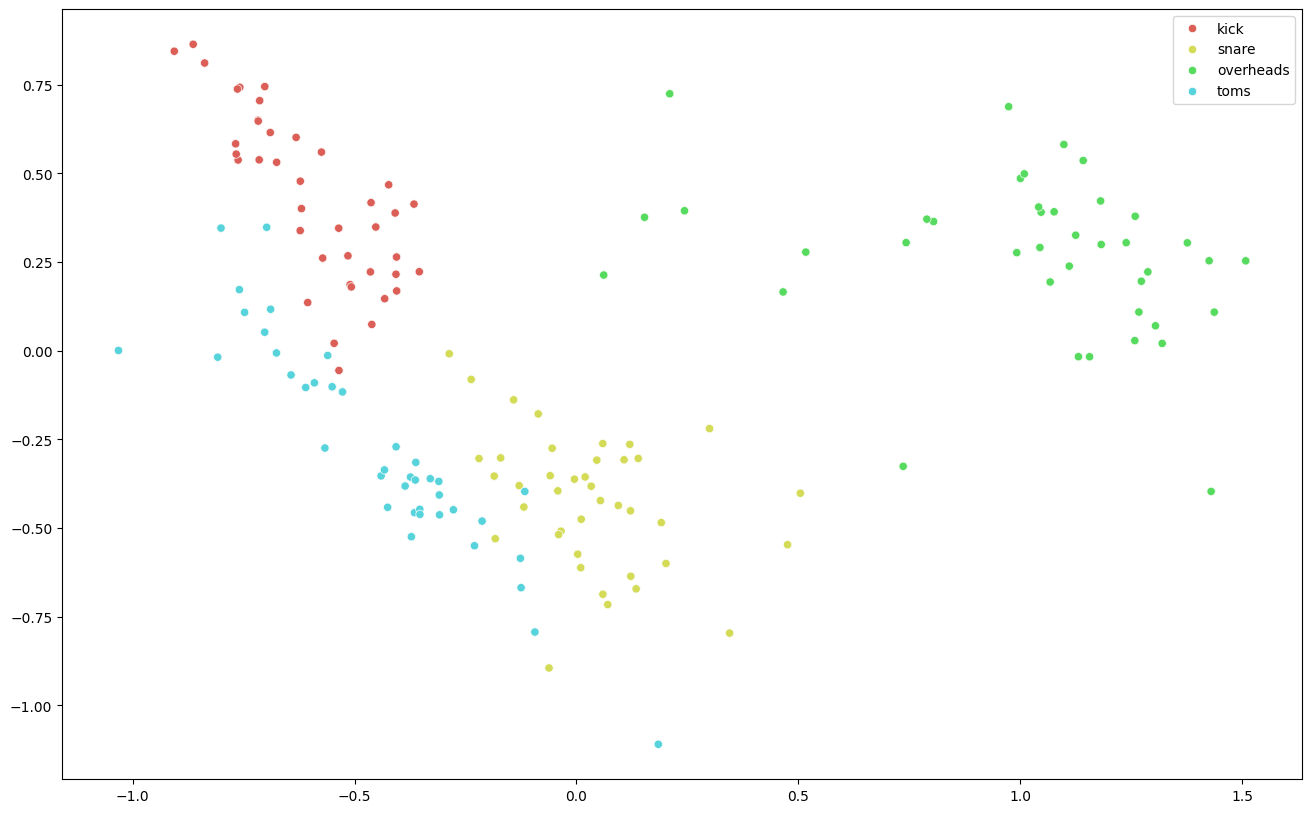

In [24]:
plt.figure(figsize=(16,10))
sns.scatterplot(
    x=X_pca[:,0], y=X_pca[:,1],
    hue=Y,
    palette=sns.color_palette("hls"),
    legend="full",
)


In [ ]:
# T-SNE

tsne = TSNE(n_components=2, learning_rate='auto', init="random", perplexity=40)
X_tsne = tsne.fit_transform(X_norm)

plt.figure(figsize=(16,10))
sns.scatterplot(
    x=X_tsne[:,0], y=X_tsne[:,1],
    hue=Y,
    palette=sns.color_palette("hls"),
    legend="full",
)
